# Human Activity Recognition with Smartphones

**Hands-on Machine Learning**

**Group members:** PETRIT Frédéric-Henri, Celin--Davanture Guilian, JIN Céline

## 1. Introduction

Human Activity Recognition (HAR) consists of automatically identifying physical activities performed by individuals using data collected from sensors.

Smartphones contain sensors like accelerometers and gyroscopes, which capture human movements and changes in orientations in time series, providing input data to classify human activities. In our case the time series were tabulated with measurements made on each time window.

The objective of this project is to develop and evaluate machine learning models capable of classifying six human activities:

- Walking
- Walking Upstairs
- Walking Downstairs
- Sitting
- Standing
- Laying

We use the *Human Activity Recognition Using Smartphones* dataset, which contains 10,299 observations and 561 extracted features from smartphone sensor measurements.

The dataset was collected from 30 volunteers performing six different activities.

**Source:** https://www.kaggle.com/uciml/human-activity-recognition-with-smartphones

### Research Question

How do different dimensionality reduction techniques affect the performance of machine learning models for smartphone-based human activity recognition?

### Evaluated Models

We are measuring and comparing the performance of 3 classic classification machine learning models for this task, and we study the impact of 2 dimensionality reduction techniques on them.

**Classification**:
- logistic regression
- support vector machine
- random forest

**Dimensionality reduction**:
- principal component analysis
- feature selection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# this makes the plots from matplotlib appear directly below the cells that generate it
%matplotlib inline

In [2]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (7352, 563)
Testing dataset: (2947, 563)


In [3]:
train_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


## 2. Data Analysis and Preprocessing

Several preprocessing steps are needed depending on the model choice.
We explore the dataset to better understand its structure and apply the needed modifications.
- assess data structure & quality, process duplicates or missing values
- ensure class distribution is balanced
- reduce the range of the features mean and variance (standardization)
- detect high correlation between features & duplicated features

We apply the appropriate modifications depending on the results, including a PCA to later compare the model's performance with and without this dimensionality reduction.

In [4]:
# general information
train_df.info()

# missing values
print("Missing values:", train_df.isnull().sum().sum())

# duplicated rows
print("Duplicated rows:", train_df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 563 entries, tBodyAcc-mean()-X to Activity
dtypes: float64(561), int64(1), str(1)
memory usage: 31.6 MB
Missing values: 0
Duplicated rows: 0


There are **7 352** observations and **563** columns.

**561** numerical features, 1 **subject identifier** `subject`, 1 **target variable** `Activity`.

There are no missing values and no duplicated rows, so no observation needs to be removed.

In [5]:
# Separate features and target
X_train = train_df.drop(columns=["Activity", "subject"])
y_train = train_df["Activity"]

X_test = test_df.drop(columns=["Activity", "subject"])
y_test = test_df["Activity"]


# Identify constant features
constant_features = X_train.columns[X_train.nunique() == 1]

print("Number of features:", X_train.shape[1])
print("Number of constant features:", len(constant_features))
print("Constant features:", constant_features.tolist())

Number of features: 561
Number of constant features: 0
Constant features: []


We also check for constant features. There are none.

`train_df.duplicated()` only compares rows. We also compare the columns, to find features whose values are identical to those of another feature on every training observation.

In [6]:
# transposing turns each feature into a row, so duplicated() compares the features
duplicated_features = X_train.columns[X_train.T.duplicated()]

# feature that each duplicate copies (duplicated() keeps the first occurrence)
identical_to = [
    next(col for col in X_train.columns if X_train[col].equals(X_train[feature]))
    for feature in duplicated_features
]

print("Number of duplicated features:", len(duplicated_features))
display(pd.DataFrame({"Duplicated feature": duplicated_features, "Identical to": identical_to}))

Number of duplicated features: 21


,Duplicated feature,Identical to
0,tBodyAccMag-sma(),tBodyAccMag-mean()
1,tGravityAccMag-mean(),tBodyAccMag-mean()
2,tGravityAccMag-std(),tBodyAccMag-std()
3,tGravityAccMag-mad(),tBodyAccMag-mad()
4,tGravityAccMag-max(),tBodyAccMag-max()
5,tGravityAccMag-min(),tBodyAccMag-min()
6,tGravityAccMag-sma(),tBodyAccMag-mean()
7,tGravityAccMag-energy(),tBodyAccMag-energy()
8,tGravityAccMag-iqr(),tBodyAccMag-iqr()
9,tGravityAccMag-entropy(),tBodyAccMag-entropy()


**21** features are exact copies of another feature. They come in two groups:
- the 13 `tGravityAccMag-*` features repeat the `tBodyAccMag-*` ones. The magnitude of gravity should be almost constant, unlike that of the body acceleration, so this is most likely an artifact of the original feature extraction;
- for the 8 other magnitude signals, `-sma()` (signal magnitude area, the mean of the absolute values) equals `-mean()`, since a magnitude is never negative.

A copied column brings no new information, but it still counts twice: after standardization it doubles the weight of the same measurement in the PCA variance and in the distances used by the SVM, Random Forest draws it twice as often among the candidate features of a split, and SelectKBest gives both copies the same F-score, so they can take two of the k selected slots.

We therefore drop the copies and keep the first occurrence of each feature, which leaves **540** features.

The duplication comes from the way the features are computed, not from the subjects in the sample, so removing these columns before cross-validation does not leak information from the validation folds. The columns are identified on the training set only, and the same columns are removed from the test set.

In [7]:
# the duplicates are found on the training set; the test set loses the same columns
X_train = X_train.drop(columns=duplicated_features)
X_test = X_test.drop(columns=duplicated_features)

print("Number of features:", X_train.shape[1])

Number of features: 540


### 2.1 Class Distribution

The dataset contains six activities: LAYING, SITTING, STANDING, WALKING, WALKING_UPSTAIRS, and WALKING_DOWNSTAIRS.

Let's count how many observations exist for each of these activities.

Activity
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986
Name: count, dtype: int64


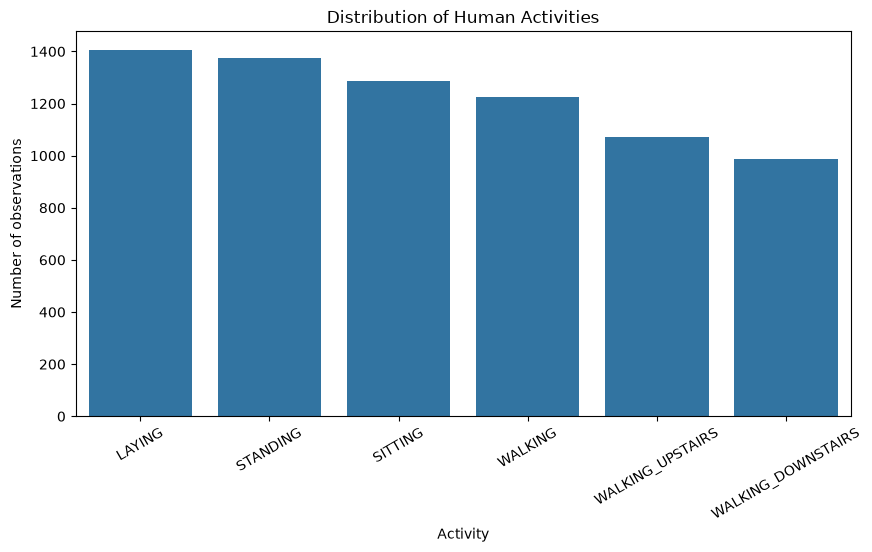

In [8]:
print(train_df["Activity"].value_counts())

# figsize in inches
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="Activity",
    order=train_df["Activity"].value_counts().index # display bars in decreasing count order, extracting category names
)

plt.title("Distribution of Human Activities")
plt.xlabel("Activity")
plt.ylabel("Number of observations")
plt.xticks(rotation=30)
plt.show()

The classes are approximately balanced (13.4% to 19.1%).

LAYING is the most frequent activity representing **19.1%** of the observations, while WALKING_DOWNSTAIRS is the least frequent representing **13.4%** of them.

As the imbalance is really moderate, we do not apply resampling techniques.

In addition to using accuracy to evaluate our models, we will also use a **macro-averaged F1-score**.

This gives each class equal weight when computing the average of the per-class F1-score.

### 2.2 Descriptive Statistics

We are just computing simple metrics on each feature, including the mean and standard deviation to normalize them.

This is important especially for SVMs and distance sensitive kernels, also for logistic regression, and usually not needed for random forests.

This is also really important for PCA because a large variance feature can then dominate in the extracted components. PCA maximizes retained variance.

We can see small differences between feature means and variance despite these approximately being contained in a reasonable range.

Taking this into account, we are using `StandardScaler` in our preprocessing.

In [9]:
# Display summary statistics for the first 15 features
X_train.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,7352.0,0.274488,0.070261,-1.000000,0.262975,0.277193,0.288461,1.000000
tBodyAcc-mean()-Y,7352.0,-0.017695,0.040811,-1.000000,-0.024863,-0.017219,-0.010783,1.000000
tBodyAcc-mean()-Z,7352.0,-0.109141,0.056635,-1.000000,-0.120993,-0.108676,-0.097794,1.000000
tBodyAcc-std()-X,7352.0,-0.605438,0.448734,-1.000000,-0.992754,-0.946196,-0.242813,1.000000
tBodyAcc-std()-Y,7352.0,-0.510938,0.502645,-0.999873,-0.978129,-0.851897,-0.034231,0.916238
tBodyAcc-std()-Z,7352.0,-0.604754,0.418687,-1.000000,-0.980233,-0.859365,-0.262415,1.000000
tBodyAcc-mad()-X,7352.0,-0.630512,0.424073,-1.000000,-0.993591,-0.950709,-0.292680,1.000000
tBodyAcc-mad()-Y,7352.0,-0.526907,0.485942,-1.000000,-0.978162,-0.857328,-0.066701,0.967664
tBodyAcc-mad()-Z,7352.0,-0.606150,0.414122,-1.000000,-0.980251,-0.857143,-0.265671,1.000000
tBodyAcc-max()-X,7352.0,-0.468604,0.544547,-1.000000,-0.936219,-0.881637,-0.017129,1.000000


In [ ]:
scaler = StandardScaler()

# standardization fitted on the training set, only to explore the PCA in Section 2.4
# the models refit their own scaler inside each cross-validation fold
X_train_scaled = scaler.fit_transform(X_train)

### 2.3 Highly correlated features

We compute a Pearson correlation matrix on the training dataset to identify highly correlated and therefore redundant pairs of features.

**1 746** feature pairs had an absolute correlation greater than **0.95**.

There are **540** features so **540 choose 2** = **145 530** pairs. This means that **1.20%** of our feature pairs are highly correlated.

This result motivates the evaluation of feature selection and principal component analysis to assess how well dimensionality can be reduced while maintaining classification performance or even increase accuracy.

In [11]:
# compute correlations between features
corr_matrix = X_train.corr().abs()

# keep only unique feature pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# count highly correlated feature pairs
high_corr_pairs = (upper_triangle > 0.95).sum().sum()

print("Highly correlated feature pairs:", high_corr_pairs)

Highly correlated feature pairs: 1746


### Example with tBodyAcc-std()-X to show high dependence

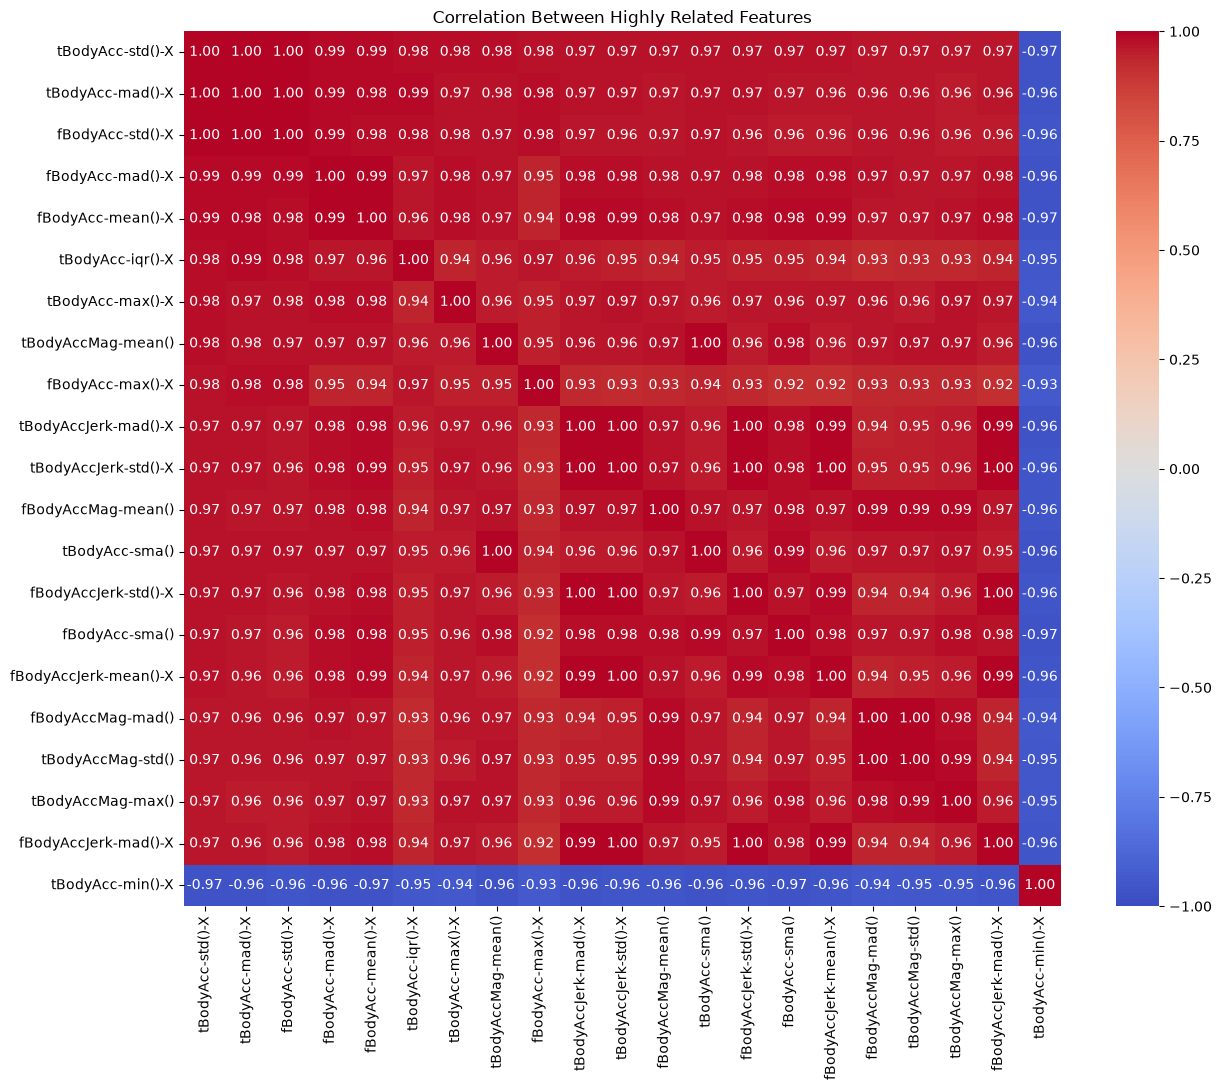

In [12]:
target_feature = "tBodyAcc-std()-X"

correlations = (
    X_train.corr()[target_feature]
    .drop(target_feature)
    .abs()
    .sort_values(ascending=False)
)

top_features = correlations.head(20).index

selected_columns = [target_feature] + list(top_features)

plt.figure(figsize=(13, 11))

sns.heatmap(
    X_train[selected_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Highly Related Features")
plt.tight_layout()
plt.show()

### 2.4 PCA reasonable minimum number of components

We apply PCA to the standardized training features to know how much of the variance can be retained using fewer dimensions.

We compute the minimum number of principal components required to preserve at least 95% of the total variance.

Further classification experiments are needed to assess the impact of the PCA on using subsequent models.

Here we just need to determine the most efficient PCA that will not be too aggressive.

Original features: 540
Components for 95% variance: 103


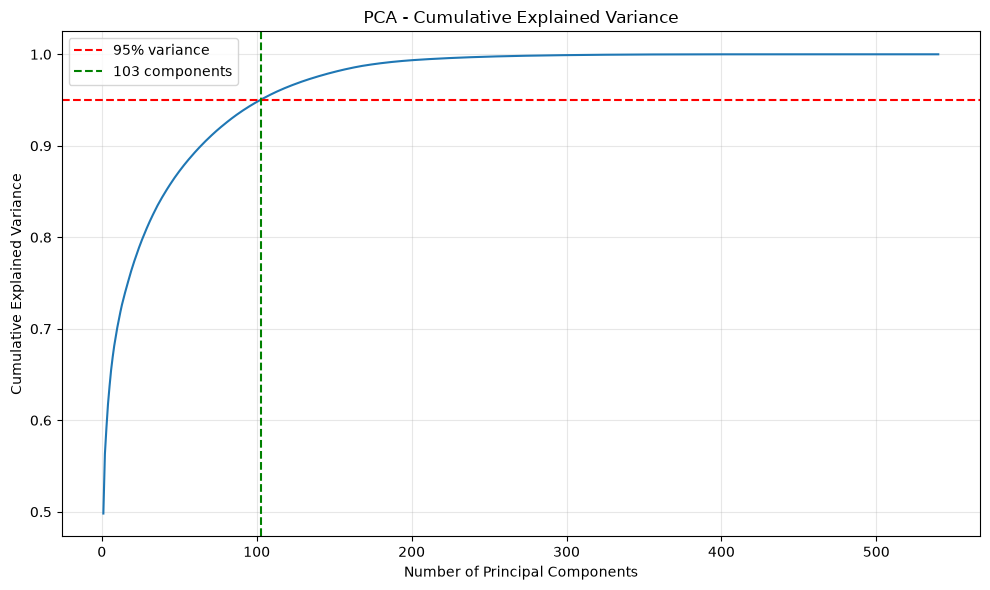

In [13]:
# fit PCA on standardized features
pca = PCA()
pca.fit(X_train_scaled)

# compute cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find the number of components explaining 95% of the variance
n_components_95 = np.searchsorted(cumulative_variance, 0.95) + 1

print(f"Original features: {X_train.shape[1]}")
print(f"Components for 95% variance: {n_components_95}")

# Plot cumulative explained variance
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.axhline(0.95, color="red", linestyle="--", label="95% variance")
plt.axvline(
    n_components_95,
    color="green",
    linestyle="--",
    label=f"{n_components_95} components"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The results show that 103 (out of 540) principal components are sufficient to explain at least 95% of the total variance.

We reduced the dimension count by 80.9%.

The explained variance curve increases rapidly for the first components before slowing down: much of the variance can be retained using a small number of components.

PCA retaining much of the variance does not guarantee a close to equally accurate classification.

We are evaluating this phenomenon, by comparing models using all 540 original features with models using the PCA components that retain 95% of the variance.

This PCA is fitted once on the whole training set and only serves this exploration: the variance curve and the choice of the 95% threshold. No model is trained on its output. In Sections 3 and 4, the scaler and the PCA are refitted inside each cross-validation fold through a `Pipeline`, so the validation subjects never influence them. The number of retained components can therefore vary slightly from one fold to another.

## 3. Model Training

### 3.1 Logistic Regression Baseline

We use Logistic Regression as our baseline classification model, trained on all 540 original features (the 561 features of the dataset minus the 21 duplicated ones).

To evaluate its ability to generalize to unseen individuals, we use subject-aware cross-validation, ensuring that observations from the same participant are not shared between training and validation sets. 

We avoid what is called subject or participant leakage. If the cross validation is not participant aware the model may benefit from person-specific learned patterns and still not generalize well to new people.

For each configuration, we report the mean score over the five folds and the standard deviation of the accuracy across folds (sample standard deviation, `ddof=1`). Each fold holds out different subjects, so the standard deviation shows how much performance depends on who is being classified. It also gives the scale against which differences between configurations should be read.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline

# identify participants 
groups = train_df["subject"]

# 5 folds separating the participants
cv = GroupKFold(n_splits=5)

# log reg pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000))
])

# evaluate the model using cross-validation
lr_scores = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display evaluation results
print(f"Mean Accuracy: {lr_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {lr_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {lr_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9352
Std Accuracy:  0.0435
Mean F1-macro: 0.9340


### 3.2 Logistic Regression with PCA

We now evaluate the impact of PCA on Logistic Regression performance.

PCA is applied after standardization to reduce dimensionality while retaining at least 95% of the variance.

We use the same subject-aware cross-validation strategy as the baseline to ensure a fair comparison. Both standardization and PCA are fitted within each training fold to avoid data leakage.

The results will be compared with the baseline model trained on all 540 features.

In [15]:
# Pipeline: StandardScaler + PCA + Logistic Regression
lr_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Evaluate using subject-aware cross-validation
lr_pca_scores = cross_validate(
    lr_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {lr_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {lr_pca_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {lr_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9208
Std Accuracy:  0.0463
Mean F1-macro: 0.9188


Logistic Regression achieved a mean accuracy of 92.08% and a macro F1-score of 91.88% after applying PCA to retain at least 95% of the variance.

Compared with the baseline using all 540 features, accuracy decreased by 1.4 percentage points, while macro F1-score decreased by 1.5 points.

These results suggest that PCA can reduce dimensionality while maintaining high classification performance.

However, the original feature representation achieved better predictive performance.

### 3.3 SVM Baseline

We use a Support Vector Machine (SVM) with an RBF kernel as our second baseline model, trained on all 540 original features.

The model is evaluated using the same subject-aware cross-validation strategy and performance metrics as Logistic Regression to ensure a fair comparison.

In [16]:
from sklearn.svm import SVC

# Create the SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Evaluate using subject-aware cross-validation
svm_scores = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {svm_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {svm_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {svm_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9229
Std Accuracy:  0.0452
Mean F1-macro: 0.9216


### 3.4 SVM with PCA

We evaluate the impact of PCA on SVM classification performance.

PCA is applied after standardization to retain at least 95% of the variance. The SVM uses the same RBF kernel and hyperparameters as the baseline model.

We use the same subject-aware cross-validation strategy to compare performance with and without dimensionality reduction.

In [17]:
# Create the SVM pipeline with PCA
svm_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

# Evaluate using subject-aware cross-validation
svm_pca_scores = cross_validate(
    svm_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=-1
)

# Display results
print(f"Mean Accuracy: {svm_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {svm_pca_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {svm_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9088
Std Accuracy:  0.0498
Mean F1-macro: 0.9089


### 3.5 Results Logistic regression and SVM

In [18]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression",
        "SVM",
        "SVM"
    ],
    "Approach": [
        "Original Features",
        "PCA (95%)",
        "Original Features",
        "PCA (95%)"
    ],
    "Mean Accuracy": [
        lr_scores["test_accuracy"].mean(),
        lr_pca_scores["test_accuracy"].mean(),
        svm_scores["test_accuracy"].mean(),
        svm_pca_scores["test_accuracy"].mean()
    ],
    "Std Accuracy": [
        lr_scores["test_accuracy"].std(ddof=1),
        lr_pca_scores["test_accuracy"].std(ddof=1),
        svm_scores["test_accuracy"].std(ddof=1),
        svm_pca_scores["test_accuracy"].std(ddof=1)
    ],
    "Mean F1-macro": [
        lr_scores["test_f1_macro"].mean(),
        lr_pca_scores["test_f1_macro"].mean(),
        svm_scores["test_f1_macro"].mean(),
        svm_pca_scores["test_f1_macro"].mean()
    ]
})

display(comparison.round(4))

,Model,Approach,Mean Accuracy,Std Accuracy,Mean F1-macro
0,Logistic Regression,Original Features,0.9352,0.0435,0.9340
1,Logistic Regression,PCA (95%),0.9208,0.0463,0.9188
2,SVM,Original Features,0.9229,0.0452,0.9216
3,SVM,PCA (95%),0.9088,0.0498,0.9089


### 3.6 Logestic Regression compared with SVM

We used the subject-aware five-fold cross-validation to compare Logistic Regression with SVM (using RBF kernel). Logistic Regression was found to provide the highest mean accuracy of 93.52% and macro F1 score of 93.40%, compared to 92.29% accuracy and 92.16% macro F1 score for SVM.

PCA was used to preserve at least 95% of the variance and this affected classification performance for both models negatively; we observe a decline in mean accuracy of both models by 1.4%. Thus, the results suggest that it is better to keep the features in their original form under the given experimental conditions.

Thus, we can see the trade-off between dimensionality reduction and predictive performance, and next we will study whether the feature selection can provide a better compromise by retaining a part of the original features.

### 3.7 Random Forest Baseline

Random Forest combines multiple decision trees to capture nonlinear relationships between features. Unlike Logistic Regression and SVM, it does not require feature standardization.

We evaluate the model using the same five-fold subject-aware cross-validation strategy and performance metrics to ensure a fair comparison.

In [19]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest pipeline
rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate using subject-aware cross-validation
rf_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=1
)

# Display results
print(f"Mean Accuracy: {rf_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {rf_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {rf_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.9185
Std Accuracy:  0.0506
Mean F1-macro: 0.9175


### 3.8 Random Forest with PCA

We evaluate the impact of PCA on Random Forest classification performance.

PCA is applied after standardization to retain at least 95% of the variance. We use the same Random Forest hyperparameters as the baseline model.

The model is evaluated using five-fold subject-aware cross-validation to determine whether dimensionality reduction affects its classification performance.

In [20]:
# Create the Random Forest pipeline with PCA
rf_pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate using subject-aware cross-validation
rf_pca_scores = cross_validate(
    rf_pca_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "f1_macro"],
    n_jobs=1
)

# Display results
print(f"Mean Accuracy: {rf_pca_scores['test_accuracy'].mean():.4f}")
print(f"Std Accuracy:  {rf_pca_scores['test_accuracy'].std(ddof=1):.4f}")
print(f"Mean F1-macro: {rf_pca_scores['test_f1_macro'].mean():.4f}")

Mean Accuracy: 0.8527
Std Accuracy:  0.0615
Mean F1-macro: 0.8475


### Random Forest Findings

The accuracy given by Random Forest is 91.85% with a macro F1-score of 91.75% using the 540 original variables. 

However, on performing PCA with a minimum of 95% of variance retained, the accuracy drops to 85.27% and the macro F1-score to 84.75%. 

The reduction of accuracy by 6.6% is significantly higher as compared to logistic regression and SVM. 

It is possible to conclude that Random Forest uses axis-parallel decisions that lose their effectiveness when original features are replaced with PCA components.

The outcome indicates that the effect of dimensionality reduction is associated with the classification algorithm being used.

## 4. Feature Selection 

We look to see if classification can be preserved while using fewer features than what are given. 

Compared with PCA which generates new features, feature selection does not create new components, but keeps the features that are best suited for classifying activities. 

In this paper, we apply SelectKBest in conjunction with the ANOVA F-score method, with subsets of 50, 100, and 200 features. Feature selection is performed within each of the training folds thus preventing leakage of training data into the test data.

### 4.1 Logistic Regression

In [21]:
from sklearn.feature_selection import SelectKBest, f_classif

# Number of features to evaluate
feature_counts = [50, 100, 200]

lr_fs_results = []

for k in feature_counts:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", LogisticRegression(max_iter=2000))
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    lr_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(ddof=1),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

lr_fs_df = pd.DataFrame(lr_fs_results)
display(lr_fs_df.round(4))

,Features,Mean Accuracy,Std Accuracy,Mean F1-macro
0,50,0.8710,0.0392,0.8736
1,100,0.9080,0.0438,0.9061
2,200,0.9235,0.0523,0.9214


The effectiveness of feature selection process was tested for three different inputs: using 50, 100, and 200 features.

Results indicate that the prediction ability of the model improves with the increase in the number of features included in the model. 200 features yield the best output with accuracy of 92.35% and macro F1-score of 92.14%.

Compared to 540 features in the baseline model, the number of features was reduced by 63.0% while dropping the accuracy level by only 1.2%.

These results indicate that the model is capable of achieving good performance even if many features are excluded.
However, there should be more experiments to benchmark feature selection against PCA at similar number of features.

### 4.2 SVM with Feature Selection

We evaluate the impact of feature selection on SVM classification performance using an RBF kernel.

We apply SelectKBest with ANOVA F-scores to select 50, 100, and 200 features.

The same five-fold subject-aware cross-validation strategy is used to compare SVM performance with the original features and PCA.

In [22]:
# Evaluate SVM with different numbers of selected features
svm_fs_results = []

for k in [50, 100, 200]:
    svm_fs_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        ))
    ])

    scores = cross_validate(
        svm_fs_pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    svm_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(ddof=1),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

svm_fs_df = pd.DataFrame(svm_fs_results)

display(svm_fs_df.round(4))

,Features,Mean Accuracy,Std Accuracy,Mean F1-macro
0,50,0.8334,0.0403,0.8267
1,100,0.8920,0.0408,0.8919
2,200,0.9170,0.0450,0.9170


Using a higher number of features boosts SVM classification accuracy.

When 200 features are selected, SVM gives a mean accuracy of 91.70%, while applying all 540 features gives 92.29% accuracy.

This implies a dimensionality reduction of almost 63.0% and an accuracy drop of only 0.6 percentage point.

Overall, logistic regression performed better than SVM with all feature counts.

Thus, feature selection can considerably help achieve dimensionality reduction and still yield good classification results. Nevertheless, the perfect combination of model and number of chosen features will vary with the classification problem.

### 4.3 Random Forest with Feature Selection

We evaluate the impact of feature selection on Random Forest classification performance.

SelectKBest with ANOVA F-scores is used to select 50, 100, and 200 features from the original dataset.

We use the same five-fold subject-aware cross-validation strategy to compare the results with the Random Forest baseline and PCA experiments.

In [23]:
# Evaluate Random Forest with feature selection
rf_fs_results = []

for k in [50, 100, 200]:
    rf_fs_pipeline = Pipeline([
        ("selector", SelectKBest(score_func=f_classif, k=k)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        rf_fs_pipeline,
        X_train,
        y_train,
        groups=groups,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=1
    )

    rf_fs_results.append({
        "Features": k,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(ddof=1),
        "Mean F1-macro": scores["test_f1_macro"].mean()
    })

rf_fs_df = pd.DataFrame(rf_fs_results)

display(rf_fs_df.round(4))

,Features,Mean Accuracy,Std Accuracy,Mean F1-macro
0,50,0.8316,0.0433,0.8325
1,100,0.8924,0.0432,0.8892
2,200,0.9163,0.0423,0.9134



Random Forest achieved its highest feature selection accuracy of 91.63% and macro F1-score of 91.34% using 200 selected features.

Compared with the baseline using all 540 features (91.85% accuracy), this represents a dimensionality reduction of approximately 63.0%, with an accuracy decrease of only 0.2 percentage points.

Feature selection also performed considerably better than PCA retaining 95% of the variance, which achieved 85.27% accuracy. However, the two methods used different numbers of dimensions.

These results suggest that selecting relevant original features may be more suitable for Random Forest than PCA under the tested configurations.

## 5. Model Comparison and Evaluation

In this section, we compare the performance of Logistic Regression, SVM, and Random Forest across three approaches: original features, PCA, and feature selection.

All models were evaluated using five-fold subject-aware cross-validation with accuracy and macro F1-score.

Our objective is to identify the best trade-off between classification performance and dimensionality reduction before evaluating the selected model on the independent test set.

In [24]:
# Collect results from all experiments
model_results = {
    "Logistic Regression": (lr_scores, lr_pca_scores, lr_fs_df),
    "SVM": (svm_scores, svm_pca_scores, svm_fs_df),
    "Random Forest": (rf_scores, rf_pca_scores, rf_fs_df)
}

results = []

for model, (baseline, pca, fs) in model_results.items():

    # Original features and PCA
    for approach, scores, dimensions in [
        ("Original", baseline, X_train.shape[1]),
        ("PCA (95%)", pca, "≈102")
    ]:
        results.append({
            "Model": model,
            "Approach": approach,
            "Dimensions": dimensions,
            "Mean Accuracy": scores["test_accuracy"].mean(),
            "Std Accuracy": scores["test_accuracy"].std(ddof=1),
            "Mean F1-macro": scores["test_f1_macro"].mean()
        })

    # Feature selection results
    for _, row in fs.iterrows():
        results.append({
            "Model": model,
            "Approach": "SelectKBest",
            "Dimensions": int(row["Features"]),
            "Mean Accuracy": row["Mean Accuracy"],
            "Std Accuracy": row["Std Accuracy"],
            "Mean F1-macro": row["Mean F1-macro"]
        })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,Approach,Dimensions,Mean Accuracy,Std Accuracy,Mean F1-macro
0,Logistic Regression,Original,540,0.9352,0.0435,0.9340
1,Logistic Regression,PCA (95%),≈102,0.9208,0.0463,0.9188
2,Logistic Regression,SelectKBest,50,0.8710,0.0392,0.8736
3,Logistic Regression,SelectKBest,100,0.9080,0.0438,0.9061
4,Logistic Regression,SelectKBest,200,0.9235,0.0523,0.9214
5,SVM,Original,540,0.9229,0.0452,0.9216
6,SVM,PCA (95%),≈102,0.9088,0.0498,0.9089
7,SVM,SelectKBest,50,0.8334,0.0403,0.8267
8,SVM,SelectKBest,100,0.8920,0.0408,0.8919
9,SVM,SelectKBest,200,0.9170,0.0450,0.9170


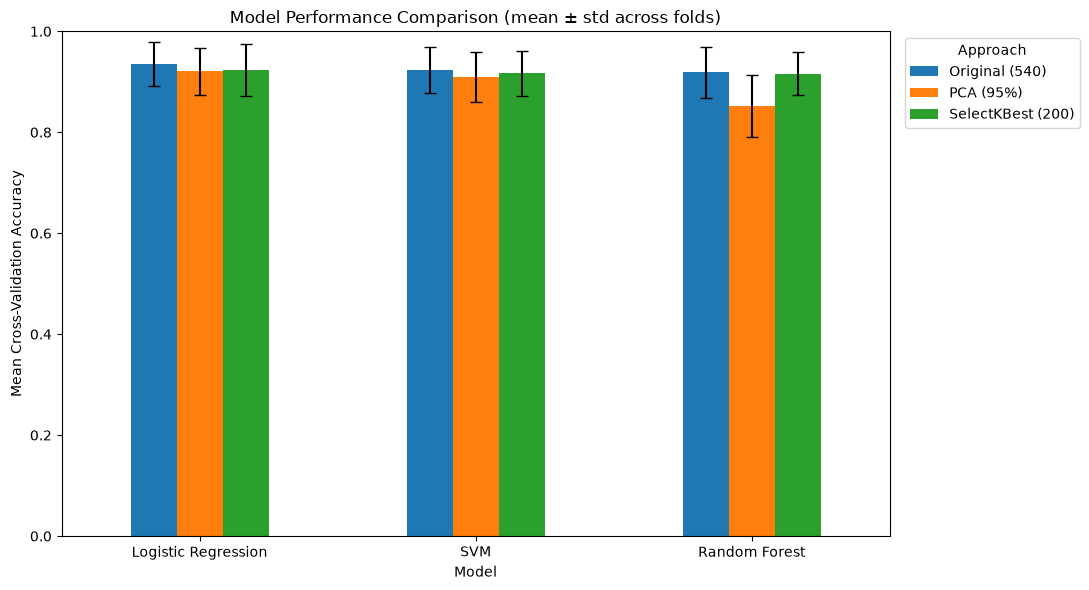

In [25]:
# Compare the main approaches
plot_df = comparison_df[
    (comparison_df["Approach"].isin(["Original", "PCA (95%)"])) |
    (
        (comparison_df["Approach"] == "SelectKBest") &
        (comparison_df["Dimensions"] == 200)
    )
].copy()

plot_df["Approach"] = plot_df["Approach"].replace({
    "Original": f"Original ({X_train.shape[1]})",
    "SelectKBest": "SelectKBest (200)"
})

# One group of bars per model, in the order of the table
models = plot_df["Model"].unique()
means = plot_df.pivot(index="Model", columns="Approach", values="Mean Accuracy").loc[models]
stds = plot_df.pivot(index="Model", columns="Approach", values="Std Accuracy").loc[models]

# Error bars show the standard deviation across the five folds
ax = means.plot.bar(yerr=stds, capsize=4, rot=0, figsize=(11, 6))

ax.set_title("Model Performance Comparison (mean ± std across folds)")
ax.set_ylabel("Mean Cross-Validation Accuracy")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.legend(title="Approach", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Logistic Regression had the mean accuracy which was 93.52% and the highest macro F1-score which was 93.40% when using all 540 original features.

Using PCA caused a drop in classification performance for all three models and the biggest drop in accuracy was for Random Forest.

Using feature selection with 200 features kept performance better for Random Forest, which had an accuracy drop of only 0.2 percentage points compared to its baseline.

PCA used fewer dimensions than the 200-feature selection method so comparing them directly depends on how much trade-off, between dimensionality and predictive performance is wanted.

Overall the results show that dimensionality reduction can keep classification performance but how well it works depends on the method and the classification algorithm.

## 6. Final Model Evaluation

Based on the cross-validation results, Logistic Regression using all 540 original features was selected as the final model, achieving the highest mean accuracy and macro F1-score.

We train the selected model on the complete training dataset and evaluate its performance on the independent test set.

We use accuracy, macro F1-score, a classification report, and a confusion matrix to assess the model's ability to recognize the six activities and identify potential classification errors.

In [26]:
# Train the selected model on the full training set
lr_pipeline.fit(X_train, y_train)

# Predict activities on the test set
y_pred = lr_pipeline.predict(X_test)

In [27]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Evaluate the final model
test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test F1-macro: {test_f1:.4f}")

# Detailed performance for each activity
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 0.9542
Test F1-macro: 0.9540

Classification Report:
                    precision    recall  f1-score   support

            LAYING       1.00      0.99      0.99       537
           SITTING       0.97      0.87      0.92       491
          STANDING       0.89      0.97      0.93       532
           WALKING       0.94      0.99      0.97       496
WALKING_DOWNSTAIRS       0.99      0.94      0.96       420
  WALKING_UPSTAIRS       0.96      0.95      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.96      0.95      0.95      2947



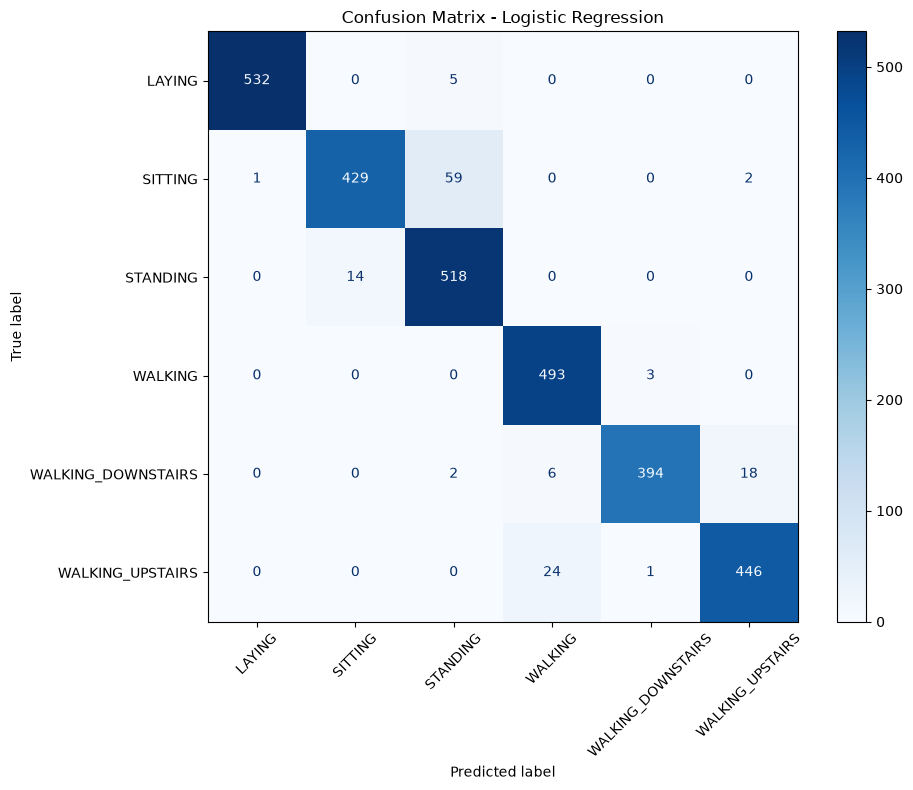

In [28]:
# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

In [29]:
# Compare cross-validation and test performance
# (the test set gives a single score, so it has no standard deviation)
final_results = pd.DataFrame({
    "Evaluation": ["Cross-validation", "Test Set"],
    "Accuracy": [
        lr_scores["test_accuracy"].mean(),
        test_accuracy
    ],
    "Std Accuracy": [
        lr_scores["test_accuracy"].std(ddof=1),
        np.nan
    ],
    "F1-macro": [
        lr_scores["test_f1_macro"].mean(),
        test_f1
    ]
})

display(final_results.round(4).fillna("–"))

,Evaluation,Accuracy,Std Accuracy,F1-macro
0,Cross-validation,0.9352,0.0435,0.934
1,Test Set,0.9542,–,0.954


### Performance–Dimensionality Trade-off

Although Logistic Regression using all 540 features achieved the highest mean cross-validation accuracy (93.52%), the difference compared with the reduced representations was relatively small.

SelectKBest with 200 features achieved 92.35% accuracy, reducing dimensionality by 63.0% with a decrease of only 1.2 percentage points.

Similarly, PCA retained at least 95% of the variance using 101 or 102 components depending on the fold, achieving 92.08% accuracy.

These results suggest that dimensionality reduction can substantially decrease the number of dimensions while preserving competitive classification performance.

Therefore, the original Logistic Regression model was selected for final evaluation based on its highest mean cross-validation performance. However, the reduced models represent promising alternatives when dimensionality is an important consideration.

## 7. Conclusion

### What we did

We classified six activities from 540 smartphone features (561 minus 21 exact duplicates) with Logistic Regression, an RBF-kernel SVM and Random Forest, and compared two dimensionality reductions: PCA keeping 95% of the variance (unsupervised, 101 or 102 components per fold) and SelectKBest with ANOVA F-scores (supervised, k = 50, 100 or 200). All configurations used the same subject-grouped five-fold cross-validation, with preprocessing fitted inside the folds. The test set was used once, for the final model.

### What worked

- **Logistic Regression on all 540 features** had the highest mean cross-validation scores (**93.52%** accuracy, **93.40%** macro F1-score) and reached **95.42%** / **95.40%** on the 9 test subjects, plausibly higher because the final model is trained on 21 subjects instead of about 17 per fold.
- **Static and dynamic activities are well separated**: only 4 of the 135 test errors mix the two groups, and LAYING is almost always recognized.
- **200 selected features** remove 63.0% of the dimensions for a loss of only 1.2 accuracy points (Logistic Regression), 0.6 (SVM) and 0.2 (Random Forest).
- **PCA** removes about 81% of the dimensions and costs 1.4 points to both Logistic Regression and SVM.

The main finding is that **the better reduction method depends on the classifier**: at about 100 dimensions, PCA beats feature selection for Logistic Regression (92.08% against 90.80%) and SVM (90.88% against 89.20%), but loses to it for Random Forest. Earlier sections found feature selection generally better only because they compared about 102 PCA components with 200 selected features.

### What did not work

- **No reduction improved accuracy**, despite the 1,746 highly correlated pairs of Section 2.3.
- **PCA with Random Forest**: accuracy falls from 91.85% to 85.27% (−6.6 points), 4 points below 100 selected features (89.24%). The components follow variance, not class separation, and mix many features, which probably hurts axis-aligned tree splits.
- **50 features** cost 6 to 9 points (83.16% to 87.10%), probably because ANOVA scores each feature alone and keeps near-copies of the same signal.
- **The model ranking is not established**: the gaps between Logistic Regression and SVM (1.2 points) or Random Forest (1.7 points) are well below the standard deviation across folds (4.4 to 5.1 points).
- **SITTING and STANDING remain confused**: 73 of the 135 test errors (59 sitting windows predicted as standing, 14 the other way), as only the phone's orientation relative to gravity differs.
- **Untested choices**: default hyperparameters, an arbitrary 95% threshold and values of k, and no measure of computation time, the main argument for reducing the dimension.

### Comparison with existing work

With a linear model and default hyperparameters, our 95.42% test accuracy is within one point (fewer than 20 of the 2,947 test windows) of the published results on the same split, about 96% for the Gaussian-kernel SVM of Anguita et al. (2013) and 95.55% for XGBoost in Gao et al. (2026), so we consider them equivalent. Both papers share our limits: SITTING versus STANDING is the hardest pair for Anguita et al., and Gao et al. lose accuracy with 100 features selected by Boruta-RFE. Our contribution is a controlled comparison of an unsupervised projection and a supervised selection across three model families under subject-grouped cross-validation, showing that neither method is best for every model.

### If we had more time

- Compare PCA and SelectKBest on the same grid of dimensions (for example 25 to 300) to check the model-dependent result beyond about 100 dimensions.
- Tune hyperparameters (C, gamma, number of trees, `max_features`), the number of components and k with `GridSearchCV` in a nested grouped cross-validation.
- Compare the models fold by fold, as they share the same held-out subjects.
- Try redundancy-aware selection (correlation filter, L1-regularized Logistic Regression, RFE), closer to Gao et al.
- Measure training and prediction times, and train a classifier dedicated to SITTING versus STANDING.

## State of the Art and Related Work

Human Activity Recognition (HAR) using smartphone sensors has been widely studied in the machine learning literature.

### Original Benchmark

Anguita et al. (2013) introduced the UCI Human Activity Recognition Using Smartphones dataset and evaluated a multiclass Support Vector Machine (SVM) using Gaussian kernels.

Their approach achieved approximately 96% classification accuracy on the official test set, consisting of 2,947 observations.

The authors also highlighted difficulties in distinguishing certain static activities, particularly SITTING and STANDING.

### Recent Research on Feature Selection

More recently, Gao et al. (2026) investigated feature selection and model interpretability using the same dataset.

Their approach combined Boruta feature selection with Random Forest-based Recursive Feature Elimination (RFE). They evaluated several classifiers, including SVM, Random Forest, and XGBoost.

Using all 561 features, XGBoost achieved 95.55% test accuracy and a macro F1-score of 95.50%.

After reducing the dataset to 100 selected features, test accuracy decreased to 93.89%, illustrating the trade-off between dimensionality reduction and classification performance.

### Comparison with Our Approach

Our project compares three classical machine learning models: Logistic Regression, SVM, and Random Forest. We investigate the effects of two dimensionality reduction approaches: Principal Component Analysis (PCA) and feature selection using SelectKBest.

Logistic Regression using all 540 original features achieved the highest mean cross-validation accuracy of 93.52%. The selected model obtained 95.42% accuracy and a macro F1-score of 95.40% on the official test set.

These results are comparable to those reported in the original benchmark and the recent XGBoost study, although differences in model configurations and evaluation procedures should be considered.

Our experiments also showed that dimensionality reduction can preserve high classification performance. In particular, SelectKBest with 200 features achieved 92.35% cross-validation accuracy with Logistic Regression, reducing dimensionality by 63.0% with an accuracy decrease of only 1.2 percentage points.

However, the impact of dimensionality reduction varied across models, with PCA causing a larger performance decrease for Random Forest.

Rather than introducing a new classification algorithm, our contribution consists of a systematic experimental comparison of classification performance, dimensionality reduction, and feature selection, using subject-aware cross-validation to assess generalization to unseen individuals.

### References

1. Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J. L. (2013). *A Public Domain Dataset for Human Activity Recognition Using Smartphones*. ESANN 2013. https://www.esann.org/sites/default/files/proceedings/legacy/es2013-84.pdf

2. Gao, H., Wang, N., Wan, Z., & Qu, R. (2026). *Compact and Explainable Human Activity Recognition with Boruta-RFE Feature Selection and SHAP Interpretation*. Applied Sciences, 16(20), 10046. https://doi.org/10.3390/app162010046